In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Find the dataset folder from the project root or this notebook folder
dataset_root = Path("LP IV Updated Datasets")
if not dataset_root.is_dir():
    dataset_root = Path("../LP IV Updated Datasets")
print("Dataset folder:", dataset_root.resolve())


Dataset folder: C:\Users\saksham\Downloads\dl\LP IV Updated Datasets\LP IV Updated Datasets


In [2]:
# Load data
train = pd.read_csv(dataset_root / "FNN and CNN/HandWritten MNIST/mnist_train.csv")
print("Training CSV shape:", train.shape)
print("Training preview (3 rows, 8 columns):\n", train.iloc[:3, :8])
print("Training label counts:\n", train["label"].value_counts().sort_index())
test = pd.read_csv(dataset_root / "FNN and CNN/HandWritten MNIST/mnist_test.csv")
print("Test CSV shape:", test.shape)
print("Test preview (3 rows, 8 columns):\n", test.iloc[:3, :8])
print("Test label counts:\n", test["label"].value_counts().sort_index())


Training CSV shape: (60000, 785)
Training preview (3 rows, 8 columns):
    label  1x1  1x2  1x3  1x4  1x5  1x6  1x7
0      5    0    0    0    0    0    0    0
1      0    0    0    0    0    0    0    0
2      4    0    0    0    0    0    0    0
Training label counts:
 label
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64
Test CSV shape: (10000, 785)
Test preview (3 rows, 8 columns):
    label  1x1  1x2  1x3  1x4  1x5  1x6  1x7
0      7    0    0    0    0    0    0    0
1      2    0    0    0    0    0    0    0
2      1    0    0    0    0    0    0    0
Test label counts:
 label
0     980
1    1135
2    1032
3    1010
4     982
5     892
6     958
7    1028
8     974
9    1009
Name: count, dtype: int64


In [3]:
# Prepare features and labels
x_train = train.iloc[0:, 1:] / 255
y_train = train.iloc[0:, 0]
x_test = test.iloc[0:, 1:] / 255
y_test = test.iloc[0:, 0]

print("Training features:", x_train.shape, "Training labels:", y_train.shape)
print("Test features:", x_test.shape, "Test labels:", y_test.shape)
print("First 10 training labels:", pd.Series(y_train).head(10).tolist())
print("Scaled training pixel range:", np.asarray(x_train).min(), np.asarray(x_train).max())
print("First image, first 10 scaled pixels:", np.asarray(x_train)[0].reshape(-1)[:10])


Training features: (60000, 784) Training labels: (60000,)
Test features: (10000, 784) Test labels: (10000,)
First 10 training labels: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]
Scaled training pixel range: 0.0 1.0
First image, first 10 scaled pixels: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [4]:
# Create model
model = Sequential([
    Dense(128, activation='relu', input_shape=(784,)),
    Dense(10, activation='softmax')
])

# Compile
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Network architecture:")
model.summary()
print("Optimizer:", type(model.optimizer).__name__)
print("Loss function:", model.loss)


Network architecture:


C:\Users\saksham\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Optimizer: SGD
Loss function: sparse_categorical_crossentropy


In [5]:
# Train
history = model.fit(x_train, y_train, epochs=11)
print("Final training epochs:")
print(pd.DataFrame(history.history).tail(3))


Epoch 1/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8361 - loss: 0.6405
Epoch 2/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9066 - loss: 0.3338
Epoch 3/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9200 - loss: 0.2850
Epoch 4/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9286 - loss: 0.2553
Epoch 5/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9349 - loss: 0.2333
Epoch 6/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9397 - loss: 0.2152
Epoch 7/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9449 - loss: 0.2001
Epoch 8/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9481 - loss: 0.1868
Epoch 9/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9512 - loss: 0.1755
Epoch 10/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9535 - loss: 0.1654
Epoch 11/11
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9566 - loss: 0.1564
Final training epochs:
    acc

In [6]:
# Evaluate and print accuracy
loss, accuracy = model.evaluate(x_test, y_test)
print("Test loss:", loss)
print("Accuracy:", accuracy * 100, "%")

# Inspect five predictions without retraining
probabilities = model.predict(np.asarray(x_test)[:5], verbose=0)
predicted = probabilities.argmax(axis=1)
actual = np.asarray(y_test)[:5]
print("First test image class probabilities:", probabilities[0].round(3))
print("First five predictions:")
print(pd.DataFrame({"True label": actual, "Predicted label": predicted}))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9547 - loss: 0.1539
Test loss: 0.15394409000873566
Accuracy: 95.46999931335449 %
First test image class probabilities: [0.    0.    0.001 0.002 0.    0.    0.    0.997 0.    0.   ]
First five predictions:
   True label  Predicted label
0           7                7
1           2                2
2           1                1
3           0                0
4           4                4


array([<Axes: >, <Axes: >], dtype=object)

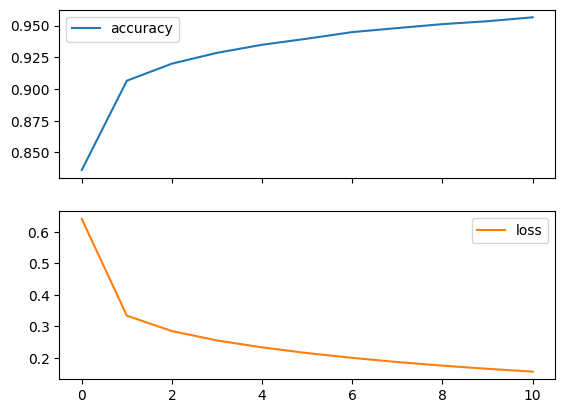

In [7]:
# Plot training loss and accuracy
pd.DataFrame(history.history).plot(subplots=True)
